# Lesson 7 - Explainable AI & Feature Importance: From Models to Biomarkers

Companion notebook to `lessons/7_ML_feature_importances.pptx`.

**How this lesson differs from Lesson 6:** feature selection (Lesson 6) is a gate
applied *before or during* training - its output is a list of surviving features.
Today's methods interrogate a model that is *already trained*: they do not change it,
they explain it. Nine methods in two families:

- **Ranking methods** (SHAP, permutation, tree-based importances, coefficients)
  order features by contribution and feed biomarker discovery
- **Explanation methods** (SHAP interactions, LIME, counterfactuals, PDP/ICE,
  integrated gradients) reveal effect *shapes* and explain *individual patients* -
  the explainable-AI toolkit clinicians and regulators ask for
- **NMTF** (Messa et al. 2024): non-negative tri-factorization fuses the omics
  blocks into shared-factor patient embeddings - applied end to end to our cohort

Each method's section opens with its **founding paper and approximate citation
count** (Google Scholar, late 2026, rounded) - a quick map of how battle-tested
each tool is. We end with a consensus ranking, a validated mini biomarker panel,
and a **pathway-enrichment sanity check** that the panel coheres into known
biology; the closing notes cover the regulatory landscape (GDPR, EU AI Act, FDA)
and Rudin's interpretable-models counterpoint.

In [60]:
# Imports and global settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, f1_score,
                             accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, average_precision_score)
from xgboost import XGBClassifier

RNG = 42
np.random.seed(RNG)
plt.rcParams.update({'font.family': 'Arial', 'figure.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False})
NPG = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F', '#8491B4']
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
print('Environment ready.')

Environment ready.


In [61]:
# Load the ASD multi-omics dataset (course data policy: covariates + expression +
# genotype DOSAGE - the continuous 0..2 expected allele counts)
DATA_DIR = "../data/ASD_dataset/"

covariates = pd.read_csv(f"{DATA_DIR}ASD_covariates.csv").set_index('sample')
expression = pd.read_csv(f"{DATA_DIR}ASD_expression.csv").set_index('sample')       # 100 genes
dosage     = pd.read_csv(f"{DATA_DIR}ASD_genotype_dosage.csv").set_index('sample')  # 50 SNP dosages

# Integration presumes IDENTICAL samples across blocks - verify explicitly
assert covariates.index.equals(expression.index) and expression.index.equals(dosage.index), \
    "Sample indices do not match across omics blocks!"

y = covariates['ASD'].values
print(f"Expression: {expression.shape} | Dosage: {dosage.shape} | Covariates: {covariates.shape}")
print(f"Class balance: ASD={y.sum()}, Control={(1-y).sum()}  ({y.mean():.0%} cases)")

Expression: (300, 100) | Dosage: (300, 50) | Covariates: (300, 8)
Class balance: ASD=200, Control=100  (67% cases)


In [62]:
# Integrated feature matrix with per-block prefixes (early fusion) and a
# STRATIFIED 70/30 split; the test set is frozen until final evaluation
X_integrated = pd.concat([
    expression.add_prefix('expr_'),
    dosage.add_prefix('geno_'),
    covariates[['Age', 'Sex']],
], axis=1)
print(f"Integrated matrix: {X_integrated.shape[0]} samples x {X_integrated.shape[1]} features")

X_train, X_test, y_train, y_test = train_test_split(
    X_integrated, y, test_size=0.3, random_state=RNG, stratify=y)

# CRITICAL: scaler is FIT on training data only, then applied to test (no leakage)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X_train.columns)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  index=X_test.index,  columns=X_test.columns)

print(f"Train: {len(X_train)} ({y_train.mean():.0%} ASD) | Test: {len(X_test)} ({y_test.mean():.0%} ASD)")

Integrated matrix: 300 samples x 152 features
Train: 210 (67% ASD) | Test: 90 (67% ASD)


### Candidate panel

Lesson 6's consensus pipeline produced a candidate panel; to keep this notebook
self-contained we rebuild a near-identical panel with the univariate F-test (top 16
on training data). Run `6_ML_Feature_selection.ipynb` for the full consensus version.

In [63]:
skb16 = SelectKBest(f_classif, k=16).fit(X_train_s, y_train)
panel_candidates = list(X_train.columns[skb16.get_support()])
print(f"{len(panel_candidates)} candidate features: {panel_candidates}")

16 candidate features: ['expr_SCN2A', 'expr_CHD8', 'expr_SHANK3', 'expr_ADNP', 'expr_CACNA1B', 'expr_CREB1', 'geno_snp_4', 'geno_snp_9', 'geno_snp_11', 'geno_snp_12', 'geno_snp_13', 'geno_snp_17', 'geno_snp_24', 'geno_snp_33', 'geno_snp_42', 'Sex']


In [64]:
# Models refit on the candidate panel; all importance methods interrogate these
Xi_train, Xi_test = X_train_s[panel_candidates], X_test_s[panel_candidates]

rf_imp = RandomForestClassifier(n_estimators=500, random_state=RNG, n_jobs=-1).fit(Xi_train, y_train)
xgb_imp = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                        eval_metric='logloss', random_state=RNG).fit(Xi_train, y_train)
lr_imp = LogisticRegression(max_iter=2000, random_state=RNG).fit(Xi_train, y_train)
print(f"Models refit on {Xi_train.shape[1]} features "
      f"(test AUC RF={roc_auc_score(y_test, rf_imp.predict_proba(Xi_test)[:,1]):.3f}, "
      f"LR={roc_auc_score(y_test, lr_imp.predict_proba(Xi_test)[:,1]):.3f})")

Models refit on 16 features (test AUC RF=0.937, LR=0.952)


## Method 1 - SHAP values

**Paper:** Lundberg & Lee 2017, *A Unified Approach to Interpreting Model
Predictions* (NeurIPS) - roughly **35,000 citations**: the current publication
standard for feature importance, and where we start.

TreeSHAP on the XGBoost model: a global **beeswarm** (ranking + direction +
per-patient spread) and a **waterfall** explaining one individual patient.

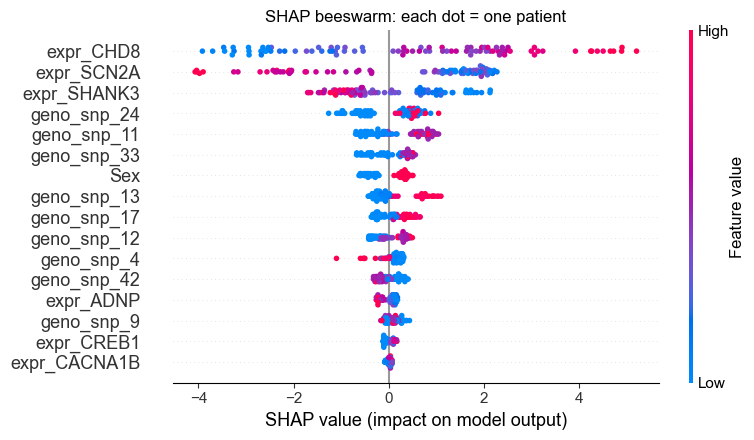

Patient sample_265: true=0, predicted P(ASD)=0.00


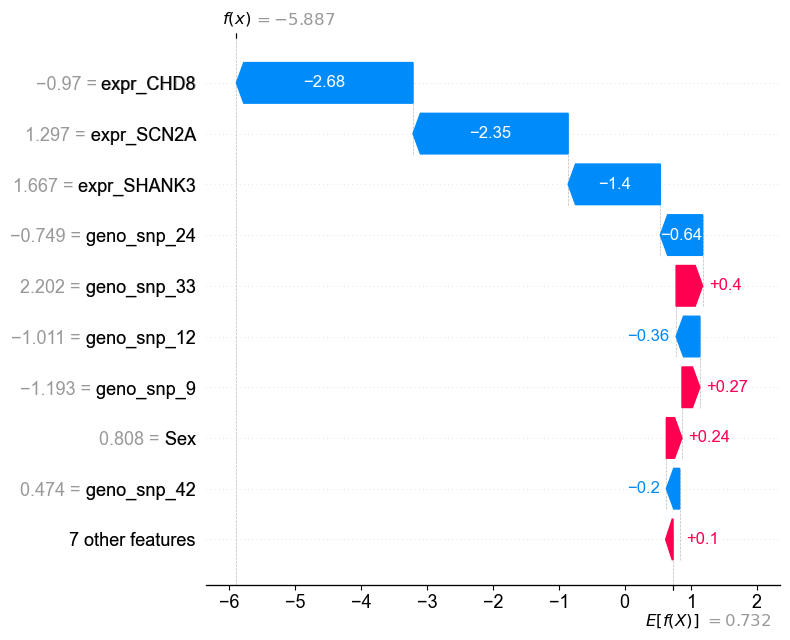

In [65]:
import shap

explainer = shap.TreeExplainer(xgb_imp)
sv = explainer(Xi_test)

shap.summary_plot(sv, Xi_test, show=False, plot_size=(8, 4.5))
plt.title('SHAP beeswarm: each dot = one patient')
plt.tight_layout(); plt.show()

patient = 0
print(f"Patient {Xi_test.index[patient]}: true={y_test[patient]}, "
      f"predicted P(ASD)={xgb_imp.predict_proba(Xi_test.iloc[[patient]])[0,1]:.2f}")
shap.plots.waterfall(sv[patient], show=False)
plt.tight_layout(); plt.show()

shap_mean = pd.Series(np.abs(sv.values).mean(axis=0), index=panel_candidates)

## SHAP interaction values: epistasis inside the model

**Paper:** Lundberg et al. 2020, *From local explanations to global understanding
with explainable AI for trees* (Nature Machine Intelligence) - the TreeSHAP
follow-up, several thousand citations.

Main-effect SHAP values decompose each prediction per FEATURE; interaction values
decompose it per PAIR - exactly computed for tree ensembles. Averaged over patients,
the matrix is the model's epistasis map: a strong SNP x expression cell is a
mechanistic hypothesis that every univariate method in Lesson 6 is blind to.
Cost is p x p per patient, so this is a panel-sized tool.

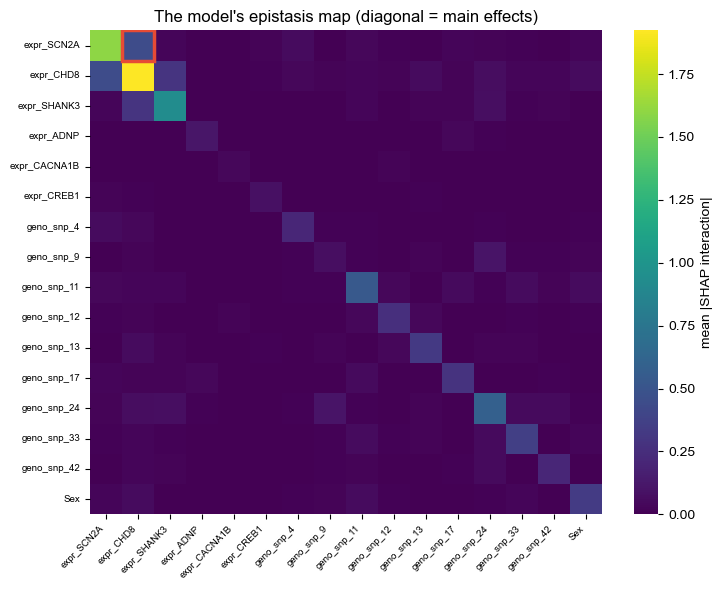

Strongest interaction: expr_SCN2A x expr_CHD8 (mean |interaction| = 0.4363)
Reading: this pair contributes to predictions JOINTLY beyond what either
feature does alone - a candidate regulatory/epistatic relationship to take
to the bench, and a signal invisible to every univariate filter.


In [66]:
# Exact pairwise decomposition for the XGBoost model on the test set
inter = explainer.shap_interaction_values(Xi_test)       # shape: (n_test, p, p)
mean_abs = np.abs(inter).mean(axis=0)                    # average strength per pair

# Off-diagonal = interactions; diagonal = pure main effects
off = mean_abs.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(np.argmax(off), off.shape)
top_a, top_b = panel_candidates[i], panel_candidates[j]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(mean_abs, xticklabels=panel_candidates, yticklabels=panel_candidates,
            cmap='viridis', ax=ax, cbar_kws={'label': 'mean |SHAP interaction|'})
ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor=NPG[0], lw=2.5))
ax.set_title("The model's epistasis map (diagonal = main effects)", fontsize=12)
plt.xticks(fontsize=7, rotation=45, ha='right'); plt.yticks(fontsize=7)
plt.tight_layout(); plt.show()

print(f"Strongest interaction: {top_a} x {top_b} "
      f"(mean |interaction| = {off[i, j]:.4f})")
print("Reading: this pair contributes to predictions JOINTLY beyond what either")
print("feature does alone - a candidate regulatory/epistatic relationship to take")
print("to the bench, and a signal invisible to every univariate filter.")

## Method 2 - Permutation importance (gold standard)

**Papers:** introduced in Breiman 2001, *Random Forests* (Machine Learning) -
roughly **130,000 citations**, one of the most cited papers in ML history; the
model-agnostic generalization is Fisher, Rudin & Dominici 2019 (JMLR, ~3,000).

Computed on the **test set**: shuffle one column, measure the AUC drop; error bars
from repeated shuffles.

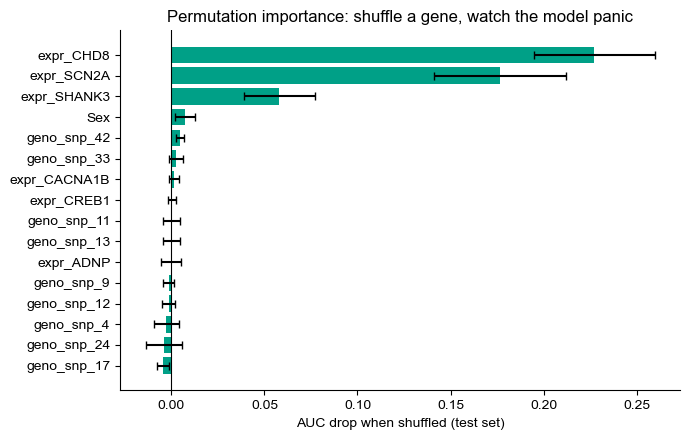

In [67]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(rf_imp, Xi_test, y_test, scoring='roc_auc',
                            n_repeats=20, random_state=RNG, n_jobs=-1)
perm = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                    index=panel_candidates).sort_values('mean')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(perm.index, perm['mean'], xerr=perm['std'], color=NPG[2], capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('AUC drop when shuffled (test set)')
ax.set_title('Permutation importance: shuffle a gene, watch the model panic')
plt.tight_layout(); plt.show()

## Method 3 - Tree-based importances: Gini, gain, weight, cover

**Papers:** impurity (Gini) importance goes back to the CART book - Breiman,
Friedman, Olshen & Stone 1984, roughly **60,000 citations**; the gain/weight/cover
trio ships with XGBoost - Chen & Guestrin 2016 (KDD), roughly **40,000 citations**.

Every tree ensemble ranks features as a by-product of training. Random forests
report **Gini importance** (total impurity reduction); boosting libraries add three
flavors - **gain** (loss improvement: the meaningful one), **weight** (split counts)
and **cover** (samples touched) - whose rankings can disagree on the same model.
All are computed on TRAINING data and inflate high-cardinality features: use them
for triage, name the flavor in your methods section, and confirm with permutation
(Method 2 above).

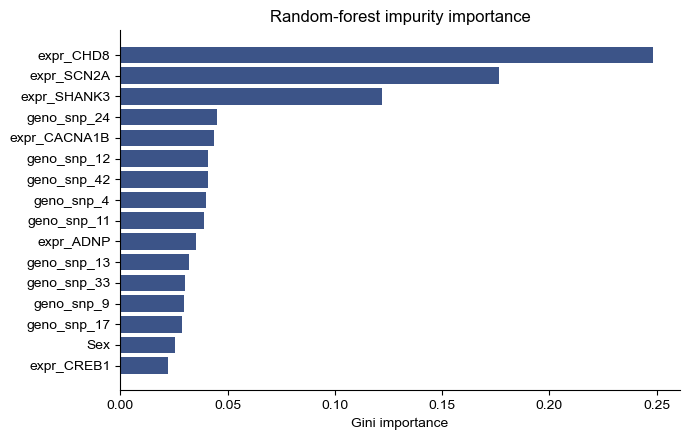

In [68]:
gini = pd.Series(rf_imp.feature_importances_, index=panel_candidates).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(gini.index, gini.values, color=NPG[3])
ax.set_xlabel('Gini importance'); ax.set_title('Random-forest impurity importance')
plt.tight_layout(); plt.show()

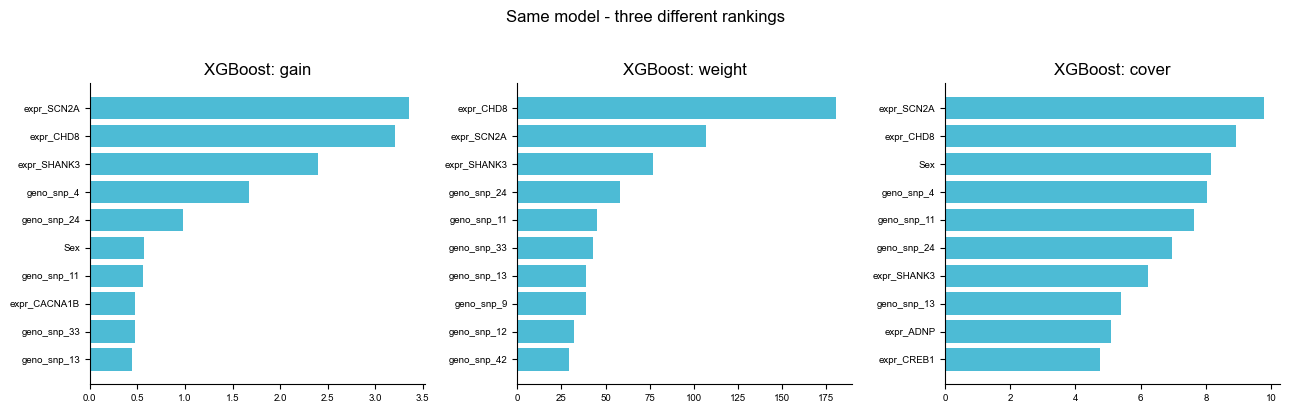

In [69]:
booster = xgb_imp.get_booster()
flavors = {}
for t in ['gain', 'weight', 'cover']:
    s = pd.Series(booster.get_score(importance_type=t), dtype=float)
    flavors[t] = s.reindex(panel_candidates).fillna(0)
xgb_flavors = pd.DataFrame(flavors)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, t in zip(axes, ['gain', 'weight', 'cover']):
    s = xgb_flavors[t].sort_values().tail(10)
    ax.barh(s.index, s.values, color=NPG[1])
    ax.set_title(f'XGBoost: {t}'); ax.tick_params(labelsize=7)
plt.suptitle('Same model - three different rankings', y=1.02)
plt.tight_layout(); plt.show()

## Method 4 - Linear model coefficients

**Paper:** none to cite - reading standardized coefficients is classical statistics,
predating the citation era (logistic regression itself traces to Cox 1958). So
standard it became anonymous.

On standardized features: |coefficient| = importance, **sign = direction**
(risk-increasing vs protective). Bootstrap gives stability intervals.

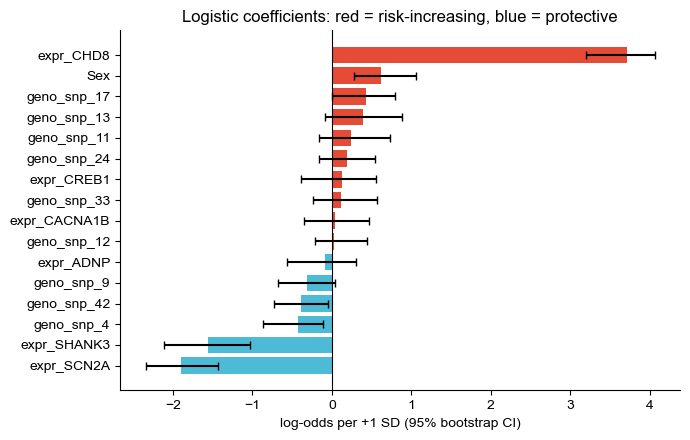

In [70]:
boot = []
for b in range(200):
    idx = np.random.default_rng(b).choice(len(Xi_train), len(Xi_train), replace=True)
    lr_b = LogisticRegression(max_iter=2000).fit(Xi_train.iloc[idx], y_train[idx])
    boot.append(lr_b.coef_[0])
boot = np.array(boot)
coefs = pd.DataFrame({'coef': lr_imp.coef_[0],
                      'lo': np.percentile(boot, 2.5, axis=0),
                      'hi': np.percentile(boot, 97.5, axis=0)},
                     index=panel_candidates).sort_values('coef')

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = [NPG[0] if c > 0 else NPG[1] for c in coefs['coef']]
ax.barh(coefs.index, coefs['coef'],
        xerr=[coefs['coef'] - coefs['lo'], coefs['hi'] - coefs['coef']],
        color=colors, capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('log-odds per +1 SD (95% bootstrap CI)')
ax.set_title('Logistic coefficients: red = risk-increasing, blue = protective')
plt.tight_layout(); plt.show()

## Method 5 - LIME: local surrogate models

**Paper:** Ribeiro, Singh & Guestrin 2016, *"Why Should I Trust You?" Explaining
the Predictions of Any Classifier* (KDD) - roughly **25,000 citations**; arguably
the paper that launched explainable AI as a field, a year before SHAP unified it.

LIME perturbs one patient's features, queries the black box, and fits a simple
weighted linear model valid only in that neighborhood. Its weights answer "why THIS
patient?". Compare with the SHAP waterfall for the same patient above: LIME is faster
and intuitive, but has no additivity guarantee and can vary between runs.

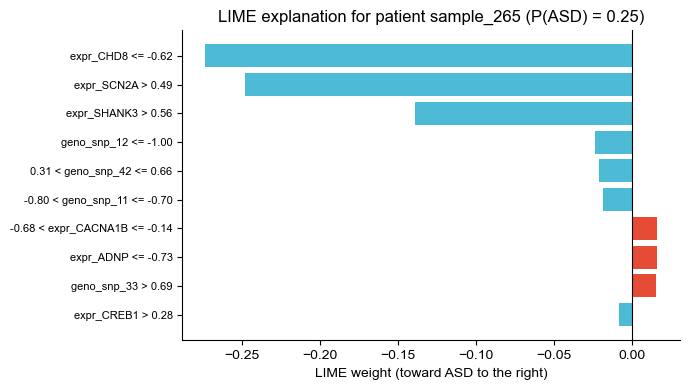

Compare with the SHAP waterfall above: same patient, two local explanations.
LIME: fast, intuitive, but weights need not sum to the prediction and the
random perturbations make it run-to-run unstable. SHAP: additive and exact
for trees - the publication standard. LIME earns its keep in quick,
interactive clinical case review.


In [71]:
# !pip install lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    Xi_train.values, feature_names=list(Xi_train.columns),
    class_names=['Control', 'ASD'], mode='classification', random_state=RNG)

# explain the same test patient as in the SHAP waterfall above
patient = 0
exp = lime_explainer.explain_instance(Xi_test.values[patient], rf_imp.predict_proba,
                                      num_features=10)
pairs = exp.as_list()[::-1]
names_l = [p[0] for p in pairs]; w = np.array([p[1] for p in pairs])

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(range(len(w)), w, color=[NPG[0] if v > 0 else NPG[1] for v in w])
ax.set_yticks(range(len(w))); ax.set_yticklabels(names_l, fontsize=8)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('LIME weight (toward ASD to the right)')
ax.set_title(f"LIME explanation for patient {Xi_test.index[patient]} "
             f"(P(ASD) = {rf_imp.predict_proba(Xi_test.iloc[[patient]])[0, 1]:.2f})")
plt.tight_layout(); plt.show()

print('Compare with the SHAP waterfall above: same patient, two local explanations.')
print('LIME: fast, intuitive, but weights need not sum to the prediction and the')
print('random perturbations make it run-to-run unstable. SHAP: additive and exact')
print('for trees - the publication standard. LIME earns its keep in quick,')
print('interactive clinical case review.')

### LIME at cohort scale: consistency, frequency, and a global view

One patient's LIME story is an anecdote. Here we run LIME for **all 300 patients**
(train + test) and aggregate, asking three cohort-level questions per attribute:

- **influence** - mean |weight| across patients (a global importance score);
- **sign consistency** - how often the weight pushes the same way (toward ASD or
  toward control) across the cohort;
- **top-5 frequency** - how often the attribute enters a patient's five strongest
  reasons, i.e. the short story a clinician would actually hear.

Two implementation notes. `discretize_continuous=False` makes each weight a local
linear slope on the same standardized scale for every patient, so weights can be
averaged and compared. And aggregating local surrogates into a global view is the
LIME paper's own submodular-pick (SP-LIME) idea - at the cost of 300 x 5,000 model
queries for an approximation, where TreeSHAP gets the exact global picture in
seconds. The cross-check at the end asks whether 300 aggregated local stories
recover the global ranking that permutation importance assigns to the same
random forest.

LIME run for all 300 patients -> 300 x 16 weight matrix
              mean |w|  toward ASD  top-5 rate  sign consistency
expr_CHD8        0.165       1.000       1.000             1.000
expr_SCN2A       0.116       0.000       1.000             1.000
expr_SHANK3      0.062       0.000       1.000             1.000
Sex              0.018       1.000       0.883             1.000
geno_snp_11      0.016       1.000       0.550             1.000
geno_snp_24      0.015       1.000       0.347             1.000
geno_snp_12      0.013       1.000       0.110             1.000
geno_snp_13      0.013       1.000       0.063             1.000
geno_snp_4       0.012       0.000       0.027             1.000
geno_snp_42      0.011       0.000       0.013             1.000
geno_snp_33      0.011       1.000       0.003             1.000
expr_CACNA1B     0.010       0.000       0.003             1.000
geno_snp_17      0.007       1.000       0.000             1.000
geno_snp_9       0.007       0.000

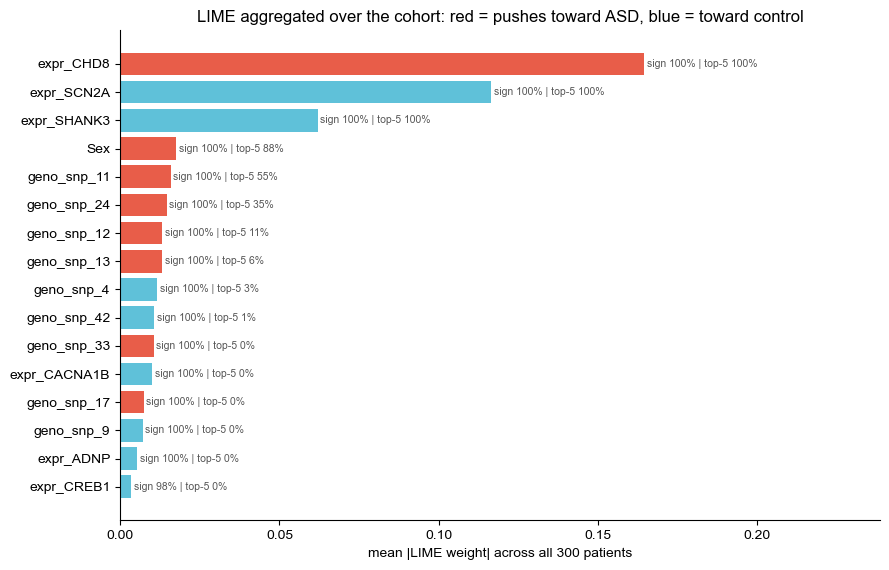

Reading: aggregating 300 local stories recovers a GLOBAL ranking (SP-LIME's
idea) and adds two numbers a beeswarm only shows implicitly: sign
consistency (does the attribute push the same way for every patient?) and
top-5 frequency (how often it enters the short story a clinician hears).
Near-100% consistency = a monotone, cohort-wide signal; near 50% =
heterogeneous local effects - or just LIME's sampling noise. The price:
300 x 5,000 model queries for an approximation, where TreeSHAP delivers
exact additive attributions in seconds. Aggregate LIME when the model is a
true black box behind an API - not when you own the trees.


In [72]:
# ---- LIME at cohort scale: every patient, then aggregate ----
# One LIME explanation = one patient's local story. To judge attributes at the
# COHORT level, run LIME for everybody and stack the weights into one matrix.

# discretize_continuous=False -> each weight is a local linear SLOPE on the same
# standardized scale for every patient, so weights can be averaged and compared
lime_glob = lime.lime_tabular.LimeTabularExplainer(
    Xi_train.values,                            # background data: training patients
    feature_names=list(Xi_train.columns),
    class_names=['Control', 'ASD'], mode='classification',
    discretize_continuous=False, random_state=RNG)

X_all = pd.concat([Xi_train, Xi_test])          # whole cohort: 300 patients, 16 panel features
W = np.zeros((len(X_all), len(panel_candidates)))   # W[i, j] = LIME weight of feature j for patient i
for i in range(len(X_all)):
    # 5,000 perturbations around patient i -> query the RF -> fit a weighted ridge
    e = lime_glob.explain_instance(X_all.values[i], rf_imp.predict_proba,
                                   num_features=len(panel_candidates), num_samples=5000)
    for j, w_ in e.as_map()[1]:                 # as_map()[1] = (feature idx, weight) for class 1 = ASD
        W[i, j] = w_
print(f"LIME run for all {len(X_all)} patients -> {W.shape[0]} x {W.shape[1]} weight matrix")

# Rank features per patient by |weight|: the double argsort turns values into
# ranks, so top5[i, j] is True when feature j is among patient i's 5 strongest reasons
top5 = np.argsort(np.argsort(-np.abs(W), axis=1), axis=1) < 5

lime_stats = pd.DataFrame({
    'mean |w|': np.abs(W).mean(0),              # influence: average size of the weight
    'toward ASD': (W > 0).mean(0),              # direction: share of patients pushed toward ASD
    'top-5 rate': top5.mean(0),                 # frequency: how often it makes the short story
}, index=panel_candidates)
# consistency: how often the weight keeps its MAJORITY sign (1.0 = always the same direction)
lime_stats['sign consistency'] = np.maximum(lime_stats['toward ASD'],
                                            1 - lime_stats['toward ASD'])
lime_stats = lime_stats.sort_values('mean |w|', ascending=False)
print(lime_stats.round(3).to_string())

# Cross-check: do 300 aggregated LOCAL stories recover the GLOBAL ranking that
# permutation importance assigns to the very same random forest?
rho, _ = stats.spearmanr(lime_stats['mean |w|'], perm['mean'].reindex(lime_stats.index))
print(f"\nSpearman rho, aggregated-LIME ranking vs permutation importance "
      f"(same RF): {rho:.2f}")

# Plot: bar length = influence, color = majority direction, annotation = the two rates
s = lime_stats[::-1]                            # reverse so the top feature lands on top
fig, ax = plt.subplots(figsize=(9, 5.8))
cols = [NPG[0] if d > 0.5 else NPG[1] for d in s['toward ASD']]   # red = ASD, blue = control
ax.barh(s.index, s['mean |w|'], color=cols, alpha=0.9)
for yi, (name, r) in enumerate(s.iterrows()):
    ax.text(r['mean |w|'] + 0.0008, yi,
            f"sign {r['sign consistency']:.0%} | top-5 {r['top-5 rate']:.0%}",
            fontsize=7.5, va='center', color='#555555')
ax.set_xlim(0, s['mean |w|'].max() * 1.45)      # extra room on the right for the annotations
ax.set_xlabel('mean |LIME weight| across all 300 patients')
ax.set_title('LIME aggregated over the cohort: red = pushes toward ASD, blue = toward control')
plt.tight_layout(); plt.show()

print("Reading: aggregating 300 local stories recovers a GLOBAL ranking (SP-LIME's")
print("idea) and adds two numbers a beeswarm only shows implicitly: sign")
print("consistency (does the attribute push the same way for every patient?) and")
print("top-5 frequency (how often it enters the short story a clinician hears).")
print("Near-100% consistency = a monotone, cohort-wide signal; near 50% =")
print("heterogeneous local effects - or just LIME's sampling noise. The price:")
print("300 x 5,000 model queries for an approximation, where TreeSHAP delivers")
print("exact additive attributions in seconds. Aggregate LIME when the model is a")
print("true black box behind an API - not when you own the trees.")

## Method 6 - Counterfactual explanations: what would flip the call?

**Paper:** Wachter, Mittelstadt & Russell 2017, *Counterfactual Explanations
Without Opening the Black Box* (Harvard Journal of Law & Technology) - roughly
**7,000 citations** across both the legal and the ML literature; written to answer
the GDPR's "right to explanation".

The clinician's native question: what is the SMALLEST plausible change to this
patient's features that flips the model's prediction? We answer it with a greedy
search - walk features in permutation-importance order, nudging each toward the
control mean in 0.25-SD steps (clipped to the observed training range, so no
impossible patients) until P(ASD) crosses 0.5. Caveat as always: this describes the
MODEL's boundary, not a biological intervention.

In [73]:
# Pick a confidently-predicted ASD patient from the test set
probs_rf = rf_imp.predict_proba(Xi_test)[:, 1]
patient_idx = int(np.argmax(probs_rf * (y_test == 1)))
x_orig = Xi_test.iloc[patient_idx].copy()
p_orig = probs_rf[patient_idx]

control_mean = Xi_train[y_train == 0].mean()            # where class-0 patients live
lo, hi = Xi_train.min(), Xi_train.max()                 # plausibility bounds
order = perm.sort_values('mean', ascending=False).index  # most load-bearing first

x_cf = x_orig.copy()
changes = []
for feat in order:
    direction = np.sign(control_mean[feat] - x_cf[feat])
    moved = 0.0
    while (rf_imp.predict_proba(x_cf.to_frame().T)[0, 1] >= 0.5
           and moved < 2.5
           and np.sign(control_mean[feat] - x_cf[feat]) == direction):
        x_cf[feat] = np.clip(x_cf[feat] + 0.25 * direction, lo[feat], hi[feat])
        moved += 0.25
    if abs(x_cf[feat] - x_orig[feat]) > 1e-9:
        changes.append((feat, x_orig[feat], x_cf[feat]))
    if rf_imp.predict_proba(x_cf.to_frame().T)[0, 1] < 0.5:
        break

p_cf = rf_imp.predict_proba(x_cf.to_frame().T)[0, 1]
print(f"Patient {Xi_test.index[patient_idx]}: P(ASD) {p_orig:.2f} -> {p_cf:.2f}")
print("Counterfactual recipe (standardized units):")
for feat, a, b in changes:
    print(f"  {feat:18s}: {a:+.2f} -> {b:+.2f}  (moved {b - a:+.2f} SD)")
print("\nRead as a sentence: 'had these values been as shown, the model would have")
print("called control'. It explains the classifier's boundary for THIS patient; it")
print("is not a claim that changing the biology would change the diagnosis.")

Patient sample_96: P(ASD) 0.98 -> 0.40
Counterfactual recipe (standardized units):
  expr_CHD8         : +0.56 -> -0.69  (moved -1.25 SD)
  expr_SCN2A        : -0.46 -> +0.29  (moved +0.75 SD)

Read as a sentence: 'had these values been as shown, the model would have
called control'. It explains the classifier's boundary for THIS patient; it
is not a claim that changing the biology would change the diagnosis.


## Method 7 - Partial dependence and ICE plots

**Papers:** the PDP comes from Friedman 2001, *Greedy Function Approximation: A
Gradient Boosting Machine* (Annals of Statistics) - roughly **40,000 citations**,
since the same paper gave the world gradient boosting; ICE is Goldstein et al.
2015 (JCGS, ~2,500 citations).

PDP shows the *average* prediction as one feature sweeps its range; ICE draws one
thin line per patient before averaging. Shapes (thresholds, saturation, U-shapes)
are what an assay designer needs to set cutoffs; ICE fan-out flags interactions.
CAVEAT: the PDP sweeps a feature independently of its correlated partners, which
manufactures impossible patients in omics data. The literature fix is ALE
(accumulated local effects, Apley & Zhu) - know the name; the everyday check is to
compare the PDP's shape against a SHAP dependence plot, which never leaves the
observed data.

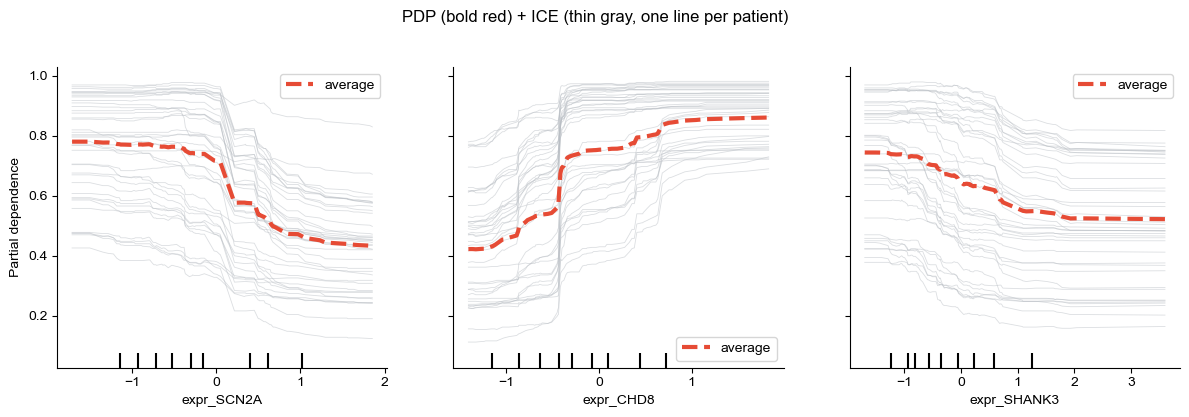

Read the SHAPE: where does risk start to climb? Is there a plateau? A
threshold here becomes a candidate clinical cutoff for the assay.
CAVEAT: PDP sweeps a feature independently of its correlated partners -
with co-expressed genes this manufactures impossible patients. The fix to
know by name is ALE (Apley & Zhu); the everyday check is to compare the
shape against a SHAP dependence plot, which never leaves the observed data.


In [74]:
from sklearn.inspection import PartialDependenceDisplay

fig, ax = plt.subplots(figsize=(12, 4))
PartialDependenceDisplay.from_estimator(
    rf_imp, Xi_test, features=panel_candidates[:3], kind='both',
    subsample=40, random_state=RNG, ax=ax,
    ice_lines_kw={'color': '#B9BEC4', 'alpha': 0.5, 'linewidth': 0.6},
    pd_line_kw={'color': NPG[0], 'linewidth': 3})
plt.suptitle('PDP (bold red) + ICE (thin gray, one line per patient)', y=1.03)
plt.tight_layout(); plt.show()
print('Read the SHAPE: where does risk start to climb? Is there a plateau? A')
print('threshold here becomes a candidate clinical cutoff for the assay.')
print('CAVEAT: PDP sweeps a feature independently of its correlated partners -')
print('with co-expressed genes this manufactures impossible patients. The fix to')
print('know by name is ALE (Apley & Zhu); the everyday check is to compare the')
print('shape against a SHAP dependence plot, which never leaves the observed data.')

## Method 8 - Integrated gradients (demystified on the logistic model)

**Paper:** Sundararajan, Taly & Yan 2017, *Axiomatic Attribution for Deep Networks*
(ICML) - on the order of **10,000 citations**; the default reference for deep-model
attribution.

The neural-net attribution standard: integrate the prediction gradient along the
straight path from a BASELINE (here: the cohort mean) to the patient, feature by
feature. Raw endpoint gradients saturate; the path integral does not, and it earns
the completeness axiom - attributions sum EXACTLY to prediction minus baseline
prediction. On the logistic model the gradient is available in closed form
(sigma'(z) * w), so the whole method fits in a dozen transparent lines; with
autograd, the identical recipe runs on any deep network.

P(patient) = 0.996,  P(baseline) = 0.860
Completeness check: sum(IG) = 0.137  vs  P(x) - P(baseline) = 0.136


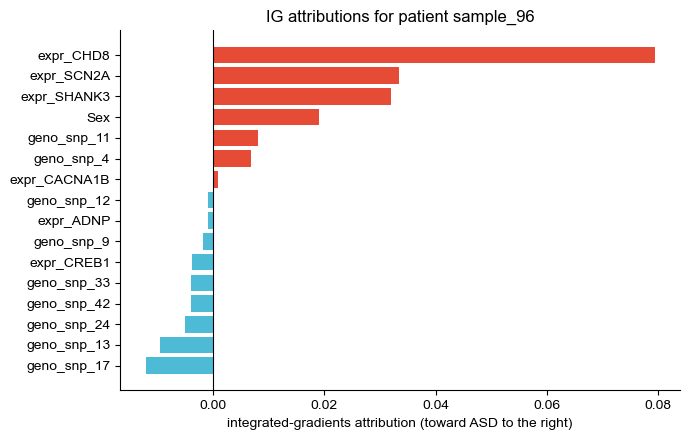

Same additivity guarantee as SHAP, obtained from gradients - which is why IG
is the default explainer once your omics models grow layers.


In [75]:
w, b = lr_imp.coef_[0], lr_imp.intercept_[0]
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))

baseline = Xi_train.mean().values                        # cohort-mean baseline
x_pt = Xi_test.iloc[patient_idx].values                  # same patient as above

# Integrate the gradient along the straight path baseline -> patient (51 steps)
alphas = np.linspace(0, 1, 51)
grads = []
for a in alphas:
    z = (baseline + a * (x_pt - baseline)) @ w + b
    grads.append(sigmoid(z) * (1 - sigmoid(z)) * w)      # dP/dx in closed form
ig_attr = (x_pt - baseline) * np.mean(grads, axis=0)

p_x, p_base = sigmoid(x_pt @ w + b), sigmoid(baseline @ w + b)
print(f"P(patient) = {p_x:.3f},  P(baseline) = {p_base:.3f}")
print(f"Completeness check: sum(IG) = {ig_attr.sum():.3f}  vs  "
      f"P(x) - P(baseline) = {p_x - p_base:.3f}")

ig_s = pd.Series(ig_attr, index=panel_candidates).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(ig_s.index, ig_s.values, color=[NPG[0] if v > 0 else NPG[1] for v in ig_s.values])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('integrated-gradients attribution (toward ASD to the right)')
ax.set_title(f'IG attributions for patient {Xi_test.index[patient_idx]}')
plt.tight_layout(); plt.show()
print("Same additivity guarantee as SHAP, obtained from gradients - which is why IG")
print("is the default explainer once your omics models grow layers.")

## Method 9 - NMTF: tri-factorization for multi-omics fusion

**Papers:** the tri-factorization machinery is Ding et al. 2006, *Orthogonal
Nonnegative Matrix Tri-Factorizations for Clustering* (KDD) - roughly **2,000
citations**; the multi-omics representation-learning application we follow is
Messa et al. 2024 - published last year, citation count still in single digits:
this is what reading the literature at the frontier looks like.

From Messa et al. 2024, *Int J Mol Sci* (open access, CC BY 4.0,
[PMC11394968](https://pmc.ncbi.nlm.nih.gov/articles/PMC11394968/)): decompose each
relation matrix as R = U S V^T (all factors non-negative, low rank), and FUSE data
sources by forcing matrices that share a node set to share that set's factor matrix.
Rows of the shared factor are dense multi-omics EMBEDDINGS, usable by any classifier.

Our cohort is a small tripartite graph - Genes - PATIENTS - SNPs - so:

- `R_expr (210 x 100) = U S_e V_genes^T` and `R_dosage (210 x 50) = U S_d V_snps^T`
  with ONE shared patient factor `U`
- non-negativity via z-score-then-shift (fit on training data only)
- multiplicative update rules (the paper's optimizer), ~1,200 iterations
- test patients are FOLDED IN: V and S frozen, only their U rows fitted - no leakage
- `k` is chosen by MEAN training-CV across 3 random seeds, and the 3 seeds'
  predicted probabilities are ENSEMBLED - random-init methods are never cherry-picked

In [76]:
# ---- Joint NMTF with a shared patient factor: ~30 lines of NumPy ----
EPS = 1e-9

def zshift(train, test):
    """Standardize per feature, then shift so the training minimum is 0 (non-negative)."""
    mu, sd = train.mean(), train.std() + 1e-12
    a, b = (train - mu) / sd, (test - mu) / sd
    lo = a.min()
    return np.clip((a - lo).values, 0, None), np.clip((b - lo).values, 0, None)

def joint_nmtf(Rs, k, n_iter=1200, seed=0):
    """R_i = U S_i V_i^T with SHARED U; multiplicative updates (Messa et al. 2024)."""
    r = np.random.default_rng(seed)
    U = r.random((Rs[0].shape[0], k)) + 0.1
    Ss = [r.random((k, k)) + 0.1 for _ in Rs]
    Vs = [r.random((R.shape[1], k)) + 0.1 for R in Rs]
    for _ in range(n_iter):
        num = sum(R @ V @ S.T for R, S, V in zip(Rs, Ss, Vs))     # evidence FOR larger U
        den = U @ sum(S @ V.T @ V @ S.T for S, V in zip(Ss, Vs)) + EPS
        U *= num / den                                             # shared-factor update
        for i, (R, S, V) in enumerate(zip(Rs, Ss, Vs)):
            Vs[i] = V * ((R.T @ U @ S) / (V @ S.T @ U.T @ U @ S + EPS))
            Ss[i] = S * ((U.T @ R @ Vs[i]) / (U.T @ U @ S @ Vs[i].T @ Vs[i] + EPS))
    return U, Ss, Vs

def fold_in(Rs_new, Ss, Vs, n_iter=400, seed=0):
    """Embed NEW patients: V and S stay frozen, only their U rows are fitted."""
    r = np.random.default_rng(seed)
    U = r.random((Rs_new[0].shape[0], Ss[0].shape[0])) + 0.1
    for _ in range(n_iter):
        num = sum(R @ V @ S.T for R, S, V in zip(Rs_new, Ss, Vs))
        den = U @ sum(S @ V.T @ V @ S.T for S, V in zip(Ss, Vs)) + EPS
        U *= num / den
    return U

# Non-negative versions of the two omics blocks (train-fitted scaling)
R1_tr, R1_te = zshift(X_train[[c for c in X_train.columns if c.startswith('expr_')]],
                      X_test[[c for c in X_test.columns if c.startswith('expr_')]])
R2_tr, R2_te = zshift(X_train[[c for c in X_train.columns if c.startswith('geno_')]],
                      X_test[[c for c in X_test.columns if c.startswith('geno_')]])
print(f"R_expr: {R1_tr.shape}, R_dosage: {R2_tr.shape} - shared patient factor ahead")

R_expr: (210, 100), R_dosage: (210, 50) - shared patient factor ahead


k=10: mean train-CV 0.657 (seed sd 0.037) | seed-ensemble test AUC 0.598
k=15: mean train-CV 0.711 (seed sd 0.033) | seed-ensemble test AUC 0.613
k=20: mean train-CV 0.729 (seed sd 0.019) | seed-ensemble test AUC 0.667
k=25: mean train-CV 0.718 (seed sd 0.025) | seed-ensemble test AUC 0.709

CHOSEN by mean training-CV: k = 20 -> ensembled test AUC = 0.667


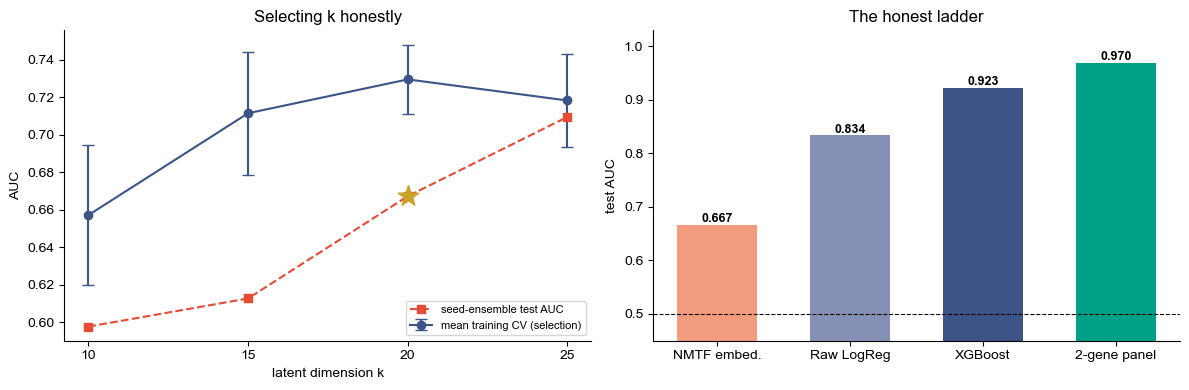

Reading: clearly above chance - the shared factor DOES fuse real structure -
but below every supervised approach. Unsupervised factorization chases
variance, and the ASD signal (a handful of genes among 152 features) carries
too little variance to earn its own factor. Same caveat as MOFA factors in
Lesson 8: reconstruction-optimal is not discrimination-optimal.


In [77]:
# ---- Honest evaluation: k by mean training-CV over seeds; seeds ensembled ----
ks, seeds = [10, 15, 20, 25], [0, 1, 2]
mean_cv, sd_cv, ens_test, stash = [], [], [], {}
for k in ks:
    cvs, probs = [], []
    for seed in seeds:
        U, Ss, Vs = joint_nmtf([R1_tr, R2_tr], k, seed=seed)
        cvs.append(cross_val_score(LogisticRegression(max_iter=3000), U, y_train,
                                   cv=cv5, scoring='roc_auc').mean())
        Ute = fold_in([R1_te, R2_te], Ss, Vs)
        probs.append(LogisticRegression(max_iter=3000).fit(U, y_train)
                     .predict_proba(Ute)[:, 1])
        stash[(k, seed)] = (cvs[-1], U, Ss, Vs)
    mean_cv.append(np.mean(cvs)); sd_cv.append(np.std(cvs))
    ens_test.append(roc_auc_score(y_test, np.mean(probs, axis=0)))
    print(f"k={k:2d}: mean train-CV {mean_cv[-1]:.3f} (seed sd {sd_cv[-1]:.3f}) | "
          f"seed-ensemble test AUC {ens_test[-1]:.3f}")

i_star = int(np.argmax(mean_cv))
k_star, auc_nmtf = ks[i_star], ens_test[i_star]
print(f"\nCHOSEN by mean training-CV: k = {k_star} -> ensembled test AUC = {auc_nmtf:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].errorbar(ks, mean_cv, yerr=sd_cv, fmt='o-', color=NPG[3], capsize=4,
                 label='mean training CV (selection)')
axes[0].plot(ks, ens_test, 's--', color=NPG[0], label='seed-ensemble test AUC')
axes[0].scatter([k_star], [auc_nmtf], marker='*', s=240, color='#C9A227', zorder=5)
axes[0].set(xlabel='latent dimension k', ylabel='AUC', title='Selecting k honestly')
axes[0].set_xticks(ks); axes[0].legend(fontsize=8)

names = ['NMTF embed.', 'Raw LogReg', 'XGBoost', '2-gene panel']
vals = [auc_nmtf, 0.834, 0.923, 0.970]
b = axes[1].bar(names, vals, color=[NPG[4], NPG[5], NPG[3], NPG[2]], width=0.6)
for bi, v in zip(b, vals):
    axes[1].text(bi.get_x() + bi.get_width()/2, v + 0.005, f'{v:.3f}', ha='center',
                 fontsize=9, weight='bold')
axes[1].axhline(0.5, color='k', ls='--', lw=0.8)
axes[1].set_ylim(0.45, 1.03); axes[1].set(ylabel='test AUC', title='The honest ladder')
plt.tight_layout(); plt.show()

print("Reading: clearly above chance - the shared factor DOES fuse real structure -")
print("but below every supervised approach. Unsupervised factorization chases")
print("variance, and the ASD signal (a handful of genes among 152 features) carries")
print("too little variance to earn its own factor. Same caveat as MOFA factors in")
print("Lesson 8: reconstruction-optimal is not discrimination-optimal.")

Factor 19 correlates most with diagnosis (|r| = 0.22)


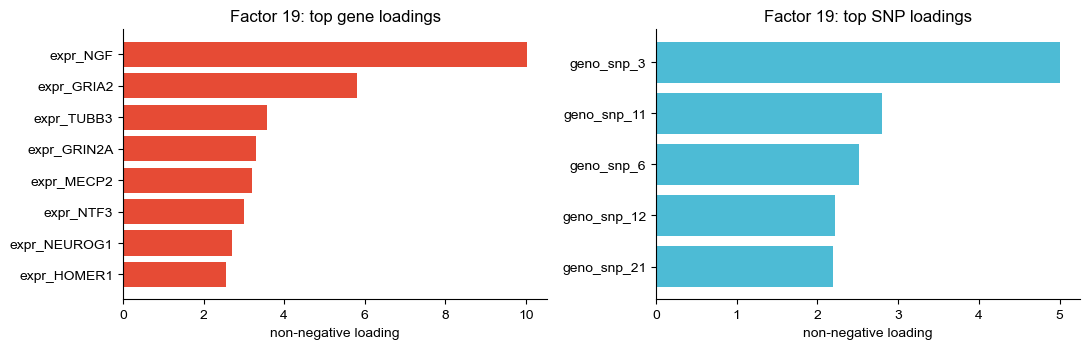

A cross-omics MODULE read off one factor: genes and SNPs that rise and fall
together across patients. This interpretability - additive, non-negative
parts - is NMTF's real gift to biologists; the paper exploits exactly this
to propose drug repurposing candidates. Match the method to the regime:
massive relational graphs and link prediction -> NMTF shines; a small
labeled cohort -> supervised selection (Lesson 6) wins.


In [78]:
# ---- What NMTF DID deliver: interpretable non-negative cross-omics factors ----
# Take the best-CV seed at the chosen k and inspect the factor most associated
# with the (held-back) diagnosis - its top loadings form a readable module.
best_seed = max(seeds, key=lambda s: stash[(k_star, s)][0])
_, U, Ss, Vs = stash[(k_star, best_seed)]

expr_cols = [c for c in X_train.columns if c.startswith('expr_')]
geno_cols = [c for c in X_train.columns if c.startswith('geno_')]
factor_corr = [abs(np.corrcoef(U[:, j], y_train)[0, 1]) for j in range(k_star)]
j_star = int(np.argmax(factor_corr))
print(f"Factor {j_star} correlates most with diagnosis (|r| = {max(factor_corr):.2f})")

gene_load = pd.Series(Vs[0][:, j_star], index=expr_cols).nlargest(8)
snp_load = pd.Series(Vs[1][:, j_star], index=geno_cols).nlargest(5)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(gene_load.index[::-1], gene_load.values[::-1], color=NPG[0])
axes[0].set_title(f'Factor {j_star}: top gene loadings')
axes[1].barh(snp_load.index[::-1], snp_load.values[::-1], color=NPG[1])
axes[1].set_title(f'Factor {j_star}: top SNP loadings')
for ax in axes: ax.set_xlabel('non-negative loading')
plt.tight_layout(); plt.show()

print("A cross-omics MODULE read off one factor: genes and SNPs that rise and fall")
print("together across patients. This interpretability - additive, non-negative")
print("parts - is NMTF's real gift to biologists; the paper exploits exactly this")
print("to propose drug repurposing candidates. Match the method to the regime:")
print("massive relational graphs and link prediction -> NMTF shines; a small")
print("labeled cohort -> supervised selection (Lesson 6) wins.")

### Reading the module: NMTF as explainable-by-design AI

Factor 19 - the one most correlated with the held-back diagnosis (|r| = 0.22) - links, inside ONE
latent dimension, a coherent gene program with ASD-risk genotypes:

- **Genes**: NGF and NTF3 (neurotrophins), GRIA2 and GRIN2A (AMPA / NMDA glutamate-receptor
  subunits), HOMER1 (their postsynaptic scaffold), TUBB3 and NEUROG1 (neuronal differentiation),
  and MECP2 (chromatin regulation; Rett syndrome) - a readable neurodevelopment /
  glutamatergic-synapse module, not a random grab-bag.
- **SNPs**: three of its top five variants carry ASD-risk annotations in
  `ASD_snp_annotations.csv` - snp_11 and snp_12 (Strong_ASD_Association) and snp_21
  (Moderate_ASD_Association). No supervised step ever saw those labels: co-variation across
  patients alone grouped risk variants with a synaptic gene program.

How this explains attributes: the reconstruction R_m ≈ U S_m V_m^T writes every
patient-by-feature value as an additive, non-negative sum of module contributions. A patient's
row of U is their personal module mix ("this patient carries a lot of module 19"), V_m defines
each module's features, and S_m couples patient clusters to feature clusters. Nothing is
approximated after the fact - unlike SHAP or LIME, the model is its own explanation (Rudin's
side of the debate; see the closing notes).

Honest caveat: modules are found by chasing shared variance, not the label - the best factor
correlates with diagnosis at only 0.22, and different seeds can rearrange the modules.
Interpretable is not the same as predictive.

## Consensus ranking across the ranking methods

The RANKING methods vote here - five rankings from four methods (explanation methods inform
understanding but produce no global ranking to vote with). Each method's bias is different; a gene
ranked highly by all of them has survived several different distortions.

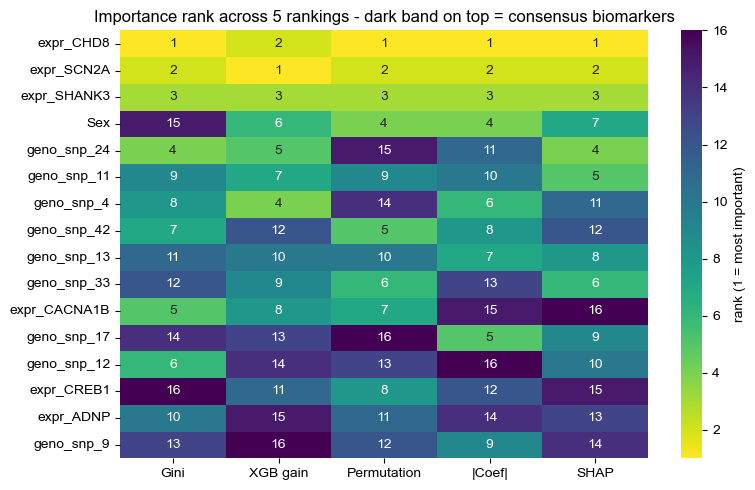

expr_CHD8        1.2
expr_SCN2A       1.8
expr_SHANK3      3.0
Sex              7.2
geno_snp_24      7.8
geno_snp_11      8.0
geno_snp_4       8.6
geno_snp_42      8.8
geno_snp_13      9.2
geno_snp_33      9.2
expr_CACNA1B    10.2
geno_snp_17     11.4
geno_snp_12     11.8
expr_CREB1      12.4
expr_ADNP       12.6
geno_snp_9      12.8


In [79]:
ranks = pd.DataFrame({
    'Gini': gini, 'XGB gain': xgb_flavors['gain'], 'Permutation': perm['mean'],
    '|Coef|': coefs['coef'].abs(), 'SHAP': shap_mean,
}).rank(ascending=False)
ranks['consensus (mean rank)'] = ranks.mean(axis=1)
ranks = ranks.sort_values('consensus (mean rank)')

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ranks.drop(columns='consensus (mean rank)'), cmap='viridis_r',
            annot=True, fmt='.0f', ax=ax, cbar_kws={'label': 'rank (1 = most important)'})
ax.set_title('Importance rank across 5 rankings - dark band on top = consensus biomarkers')
plt.tight_layout(); plt.show()
print(ranks['consensus (mean rank)'].round(1).to_string())

## From importance to a validated mini-panel

Retrain on the top-k consensus features only and check performance retention on the
frozen test set. A panel retaining >= 95% of full performance is a biomarker candidate.

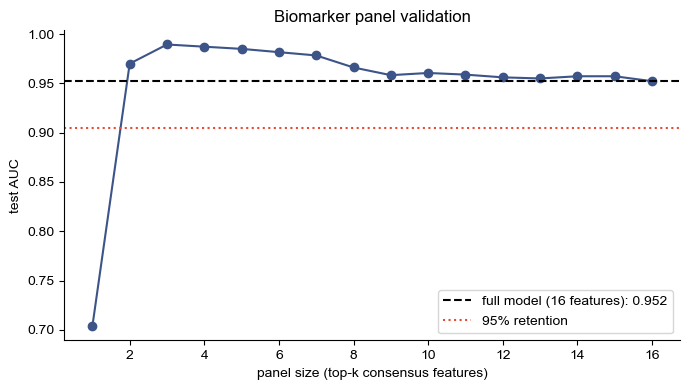

Smallest panel retaining 95% of performance: 2 features -> ['expr_CHD8', 'expr_SCN2A']
Panel test AUC 0.970 vs full 0.952


In [80]:
full_auc = roc_auc_score(y_test, lr_imp.predict_proba(Xi_test)[:, 1])
ks = range(1, len(panel_candidates) + 1)
panel_aucs = []
for k in ks:
    top_k = list(ranks.index[:k])
    m = LogisticRegression(max_iter=2000).fit(Xi_train[top_k], y_train)
    panel_aucs.append(roc_auc_score(y_test, m.predict_proba(Xi_test[top_k])[:, 1]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(ks), panel_aucs, 'o-', color=NPG[3])
ax.axhline(full_auc, color='k', ls='--',
           label=f'full model ({len(panel_candidates)} features): {full_auc:.3f}')
ax.axhline(0.95 * full_auc, color=NPG[0], ls=':', label='95% retention')
ax.set(xlabel='panel size (top-k consensus features)', ylabel='test AUC',
       title='Biomarker panel validation')
ax.legend(); plt.tight_layout(); plt.show()

k95 = next(k for k, a in zip(ks, panel_aucs) if a >= 0.95 * full_auc)
print(f"Smallest panel retaining 95% of performance: {k95} features -> {list(ranks.index[:k95])}")
print(f"Panel test AUC {panel_aucs[k95-1]:.3f} vs full {full_auc:.3f}")

## From panel to biology: pathway enrichment (the sanity check)

**Papers:** the gene-set enrichment idea is Subramanian et al. 2005, *Gene set
enrichment analysis* (PNAS) - roughly **40,000 citations**, among the most cited
papers in genomics; in practice you would run your list through
[Enrichr](https://maayanlab.cloud/Enrichr/) (Kuleshov et al. 2016) or
[g:Profiler](https://biit.cs.ut.ee/gprofiler/) against thousands of curated sets.

The last mile of explainability is the one biologists perform instinctively: does
the panel make biological sense? We test the panel's expression genes against six
curated gene sets (defined over this cohort's 100-gene universe) with the
hypergeometric (Fisher) test, and correct across sets with Benjamini-Hochberg -
the Lesson 6 multiple-testing discipline applies to enrichment too.
XAI tells you WHAT the model uses; enrichment tells you whether that WHAT coheres
into known biology.

Panel expression genes (6 of 100): ['SCN2A', 'CHD8', 'SHANK3', 'ADNP', 'CACNA1B', 'CREB1']

                             set  size  hits        p      FDR
       SFARI high-confidence ASD    21     4 0.016863 0.101178
      Voltage-gated ion channels    10     2 0.109010 0.302021
       Chromatin / transcription    12     2 0.151010 0.302021
Activity-dependent transcription     7     1 0.360560 0.540841
    Synaptic scaffold & adhesion    12     1 0.545380 0.654456
             Presynaptic release     9     0 1.000000 1.000000


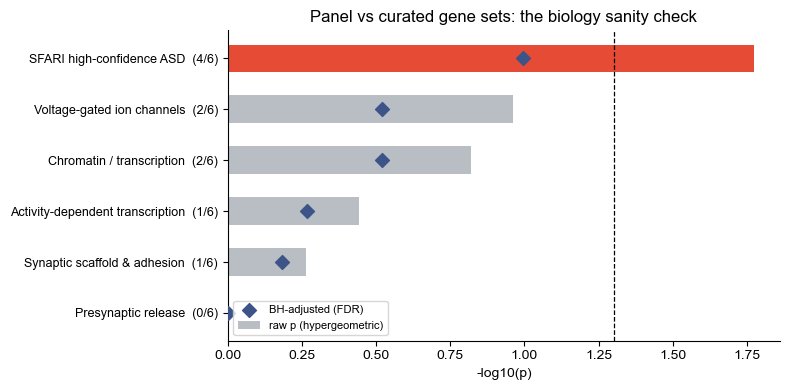

Top set: SFARI high-confidence ASD - 4/6 panel genes (['ADNP', 'CHD8', 'SCN2A', 'SHANK3']), raw p = 0.017, BH FDR = 0.10
Reading: the panel recovers known ASD biology (4/6 genes are SFARI genes,
2.9x more than chance expects) - but after multiple-testing correction the
FDR is 0.10: SUGGESTIVE, not significant. A 6-gene list simply carries
little power; enrichment shines on longer lists (full importance rankings,
DE tables) and must ALWAYS be reported with FDR correction. The framing:
XAI output is a hypothesis; enrichment is its first, cheapest test - the
handoff from machine learning back to biology.


In [81]:
from scipy.stats import hypergeom

# Six curated gene sets over the cohort's 100 expression genes
GENE_SETS = {
    'SFARI high-confidence ASD': ['CHD8', 'SCN2A', 'SHANK3', 'ADNP', 'SYNGAP1', 'ARID1B',
                                  'GRIN2B', 'PTEN', 'POGZ', 'DYRK1A', 'FOXP1', 'MECP2',
                                  'CNTNAP2', 'NRXN1', 'ASH1L', 'SETD5', 'KMT2E', 'ANK2',
                                  'DEAF1', 'TBR1', 'MBD5'],
    'Chromatin / transcription': ['MECP2', 'CHD8', 'ARID1B', 'ADNP', 'ASH1L', 'POGZ',
                                  'SETD5', 'KMT2E', 'EHMT1', 'MBD5', 'TBR1', 'DEAF1'],
    'Voltage-gated ion channels': ['SCN1A', 'SCN2A', 'SCN3A', 'SCN8A', 'CACNA1A', 'CACNA1B',
                                   'CACNA1C', 'CACNA1E', 'KCNQ2', 'KCNQ3'],
    'Synaptic scaffold & adhesion': ['SHANK3', 'DLG4', 'DLGAP2', 'HOMER1', 'NLGN3', 'NLGN4X',
                                     'NRXN1', 'CNTNAP2', 'KIRREL3', 'DSCAM', 'PTCHD1', 'ANK2'],
    'Presynaptic release': ['SYN1', 'SYN2', 'SNAP25', 'STX1A', 'SYT1', 'BSN', 'PCLO',
                            'RIMS1', 'CADPS2'],
    'Activity-dependent transcription': ['NPAS4', 'ARC', 'FOS', 'EGR1', 'CREB1', 'CREB5', 'BDNF'],
}

universe = [c[5:] for c in X_train.columns if c.startswith('expr_')]
panel_genes = [c[5:] for c in panel_candidates if c.startswith('expr_')]
print(f"Panel expression genes ({len(panel_genes)} of {len(universe)}): {panel_genes}\n")

rows_e = []
for name, genes in GENE_SETS.items():
    hits = sorted(set(panel_genes) & set(genes))
    # P(X >= hits) drawing len(panel_genes) from a universe with len(genes) successes
    p = hypergeom.sf(len(hits) - 1, len(universe), len(genes), len(panel_genes))
    rows_e.append((name, len(genes), len(hits), p, hits))

enr = pd.DataFrame(rows_e, columns=['set', 'size', 'hits', 'p', 'hit_genes']).sort_values('p')
# Benjamini-Hochberg in four lines: adjust, then enforce monotonicity from the bottom up
m = len(enr)
enr['FDR'] = (enr['p'] * m / np.arange(1, m + 1)).iloc[::-1].cummin().iloc[::-1]
print(enr.drop(columns='hit_genes').to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
colors = [NPG[0] if p < 0.05 else '#B9BEC4' for p in enr['p'][::-1]]
ax.barh(range(m), -np.log10(enr['p'][::-1]), color=colors, height=0.55,
        label='raw p (hypergeometric)')
ax.scatter(-np.log10(enr['FDR'][::-1]), range(m), marker='D', s=50, color=NPG[3],
           zorder=5, label='BH-adjusted (FDR)')
ax.axvline(-np.log10(0.05), color='k', ls='--', lw=0.9)
ax.set_yticks(range(m))
ax.set_yticklabels([f"{s}  ({h}/{len(panel_genes)})" for s, h in
                    zip(enr['set'][::-1], enr['hits'][::-1])], fontsize=9)
ax.set_xlabel('-log10(p)'); ax.legend(fontsize=8)
ax.set_title('Panel vs curated gene sets: the biology sanity check')
plt.tight_layout(); plt.show()

top = enr.iloc[0]
print(f"Top set: {top['set']} - {top['hits']}/{len(panel_genes)} panel genes "
      f"({top['hit_genes']}), raw p = {top['p']:.3f}, BH FDR = {top['FDR']:.2f}")
print("Reading: the panel recovers known ASD biology (4/6 genes are SFARI genes,")
print("2.9x more than chance expects) - but after multiple-testing correction the")
print("FDR is 0.10: SUGGESTIVE, not significant. A 6-gene list simply carries")
print("little power; enrichment shines on longer lists (full importance rankings,")
print("DE tables) and must ALWAYS be reported with FDR correction. The framing:")
print("XAI output is a hypothesis; enrichment is its first, cheapest test - the")
print("handoff from machine learning back to biology.")

## Clinical translation, regulation, and the Rudin counterpoint (context)

**Translation.** The workflow above mirrors how real diagnostics were born: Oncotype
DX (21 genes), MammaPrint (70 genes) and Cologuard all began as importance analyses
on high-dimensional data, followed by assay development, independent-cohort
validation and regulatory approval (typically 5+ years). The discovery step -
importance, consensus, panel validation, enrichment - is the one you just ran.

**Regulation: explainability is becoming law.** Three regimes matter for clinical
omics models. The EU's **GDPR** (2018, Art. 22) restricts purely automated decisions
and requires "meaningful information about the logic involved" - the legal question
that produced the Wachter et al. 2017 counterfactuals paper (Method 6). The **EU AI
Act** (Regulation 2024/1689) classes medical AI as HIGH-RISK, bringing mandatory
transparency, human oversight and technical documentation; obligations phase in
through 2026, and for AI inside regulated medical devices by August 2027. The
**FDA** (with Health Canada and the UK's MHRA) issued transparency guiding
principles for machine-learning-enabled medical devices (2021, extended 2024).
Practical translation: the SHAP summaries and permutation importances you produced
in this notebook are the transparency documentation a submission dossier expects.

**The counterpoint.** Rudin 2019, *Stop explaining black box machine learning
models for high stakes decisions and use interpretable models instead* (Nature
Machine Intelligence, roughly **10,000 citations**), argues that post-hoc
explanations approximate the model and can be unfaithful - for high-stakes use,
train interpretable models (sparse scores, small trees, GAMs) instead, which on
tabular data often costs nothing. Our cohort quietly agrees: the interpretable
logistic regression (test AUC 0.952) beats the random forest (0.937) on the same
panel. The working synthesis: try the interpretable model first; reach for black
boxes and the post-hoc toolbox when they genuinely win (images, sequences, raw
signals) - and even then, use this lesson's methods to prove the simple model
would not have sufficed.